# Stage 1 — Data Acquisition (Chlorophyll-a Target)

**Region:** Malta–Sicily Channel, 35.5–37.5° N and 12.0–15.5° E  
**Validated period:** 2021-01-01 through 2023-12-31  
**Product:** `cmems_obs-oc_med_bgc-plankton_my_l3-multi-1km_P1D`, Mediterranean multi-sensor L3 daily reprocessed observations at 1 km.

This is the prediction target. Native missing retrievals are retained: no temporal interpolation, gap filling, or substitution with model output is applied. The catalogue version and part are pinned in the configuration cell and checked before download.


### Prerequisites (from Stage 0)
- Virtual env active with `copernicusmarine>=2.4.1`, `xarray`, `netCDF4`, `dask`, `matplotlib` installed.
- `copernicusmarine login` has been run once on this machine (credentials cached in your home dir).

If either is not true, do Stage 0 first.

## 1.0 — Configuration

Keep the region box, date window, and output paths in one place so later notebooks can copy them verbatim.

In [1]:
from pathlib import Path

MINIMUM_LONGITUDE = 12.0
MAXIMUM_LONGITUDE = 15.5
MINIMUM_LATITUDE =  35.5
MAXIMUM_LATITUDE = 37.5

START = "2021-01-01T00:00:00"
END   = "2023-12-31T00:00:00"

DATASET_ID = "cmems_obs-oc_med_bgc-plankton_my_l3-multi-1km_P1D"
DATASET_VERSION = "202411"
DATASET_PART = "default"
PRODUCT_DOI = "10.48670/moi-00299"
VARIABLES  = [
    "CHL", 
    "QI_CHL", # climatological quality/anomaly index
    "SENSORMASK", # which sensors contributed
    "WTM" # Case-1/Case-2 water-type mask
] 

RAW_DIR  = Path("data/raw")
FIG_DIR  = Path("figs")
OUT_FILE = "chl_malta_2021_2023.nc"
OUT_PATH = RAW_DIR / OUT_FILE

RAW_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("Period   :", START, "→", END)
print("Dataset  :", DATASET_ID)
print("Output   :", OUT_PATH.resolve())

Period   : 2021-01-01T00:00:00 → 2023-12-31T00:00:00
Dataset  : cmems_obs-oc_med_bgc-plankton_my_l3-multi-1km_P1D
Output   : C:\GIT\mcast.pages.ai.v2\experiment\data\raw\chl_malta_2021_2023.nc


## 1.1 — Confirm the dataset ID is current

CMEMS versions its short-names occasionally. Run `describe` once before downloading so a drifted ID fails loudly here rather than silently downloading the wrong product.

> If this errors with *dataset not found*: run `copernicusmarine describe --contains "med_bgc-plankton"` in a terminal and update `DATASET_ID` above to the current granular short-name.

In [2]:
import copernicusmarine

meta = copernicusmarine.describe(
    dataset_id=DATASET_ID,
)
print("Catalogue reachable — dataset resolved OK.")
# Uncomment to see the full metadata blob:
# print(meta)

Fetching catalogue 1:  50%|█████     | 1/2 [00:00<00:00,  1.20it/s]

Catalogue reachable — dataset resolved OK.


## 1.2 — Download the CHL cube

The download is idempotent: an existing file is reused while `FORCE = False`. Set it to `True` only for an intentional replacement, then return it to `False` so rerunning the notebook does not redownload the cube.


In [3]:
FORCE = False

if OUT_PATH.exists() and not FORCE:
    size_mb = OUT_PATH.stat().st_size / 1e6
    print(f"Skipping download — {OUT_PATH.name} already exists ({size_mb:.1f} MB).")
    print("Set FORCE=True to re-download.")
else:
    copernicusmarine.subset(
        dataset_id=DATASET_ID,
        dataset_version=DATASET_VERSION,
        dataset_part=DATASET_PART,
        variables=VARIABLES,
        start_datetime=START,
        end_datetime=END,
        output_filename=OUT_FILE,
        output_directory=str(RAW_DIR),
        overwrite=FORCE,
        maximum_latitude=MAXIMUM_LATITUDE,
        maximum_longitude=MAXIMUM_LONGITUDE,
        minimum_latitude=MINIMUM_LATITUDE,
        minimum_longitude=MINIMUM_LONGITUDE
    )

    assert OUT_PATH.exists(), f"Download did not create {OUT_PATH}"

    print(
        f"Downloaded: {OUT_PATH.resolve()} "
        f"({OUT_PATH.stat().st_size / 1e6:.1f} MB)"
    )

INFO - 2026-08-20T10:35:39Z - Selected dataset version: "202411"
INFO - 2026-08-20T10:35:39Z - Selected dataset part: "default"
Fetching catalogue 1: 100%|██████████| 2/2 [00:09<00:00,  4.74s/it]


  0%|          | [00:00<?]

INFO - 2026-08-20T10:36:25Z - Total size of the download: 900.35 MB.


Downloaded: C:\GIT\mcast.pages.ai.v2\experiment\data\raw\chl_malta_2021_2023.nc (943.6 MB)


## 1.3 — Inspect the cube

The cube is opened lazily using Dask chunks. Validation uses Dask-backed reductions and materialises only scalar statistics and the small two-dimensional target-domain mask.

In [4]:
import xarray as xr

ds = xr.open_dataset(OUT_PATH, chunks={"time": 50})
ds

<xarray.Dataset> Size: 1GB
Dimensions:     (time: 1095, latitude: 198, longitude: 272)
Coordinates:
  * time        (time) datetime64[ns] 9kB 2021-01-01 2021-01-02 ... 2023-12-31
  * latitude    (latitude) float32 792B 35.5 35.51 35.52 ... 37.48 37.49 37.5
  * longitude   (longitude) float32 1kB 12.01 12.02 12.03 ... 15.46 15.47 15.49
Data variables:
    CHL         (time, latitude, longitude) float32 236MB dask.array<chunksize=(50, 198, 272), meta=np.ndarray>
    QI_CHL      (time, latitude, longitude) float32 236MB dask.array<chunksize=(50, 198, 272), meta=np.ndarray>
    SENSORMASK  (time, latitude, longitude) float64 472MB dask.array<chunksize=(50, 198, 272), meta=np.ndarray>
    WTM         (time, latitude, longitude) float32 236MB dask.array<chunksize=(50, 198, 272), meta=np.ndarray>
Attributes: (12/40)
    Conventions:               CF-1.4
    citation:                   
    cmems_product_id:          OCEANCOLOUR_MED_BGC_L3_MY_009_143
    cmems_production_unit:     OC-CNR-ROMA-IT
    comment:                   r=log10(max([rrs443,rrs490,rrs510])/rrs555) ; ...
    contact:                   technical@gos.artov.isac.cnr.it
    ...                        ...
    start_time:                08:00:00 UTC
    stop_date:                 2024-10-15
    stop_time:                 14:00:00 UTC
    title:                     cmems_obs-oc_med_bgc-plankton_my_l3-multi-1km_P1D
    westernmost_longitude:     -6.0
    copernicusmarine_version:  2.4.1

In [5]:
print("Dims     :", dict(ds.sizes))
print("Time     :", str(ds.time.values.min())[:10], "→", str(ds.time.values.max())[:10])
print("Lat range:", float(ds.latitude.min()),  "→", float(ds.latitude.max()))
print("Lon range:", float(ds.longitude.min()), "→", float(ds.longitude.max()))
print("CHL units:", ds.CHL.attrs.get("units"))
print("Variables:", list(ds.data_vars))

Dims     : {'time': 1095, 'latitude': 198, 'longitude': 272}
Time     : 2021-01-01 → 2023-12-31
Lat range: 35.5037956237793 → 37.49873352050781
Lon range: 12.005970001220703 → 15.48768138885498
CHL units: milligram m^-3
Variables: ['CHL', 'QI_CHL', 'SENSORMASK', 'WTM']


---
## Validation Gate 1

The gate verifies the acquisition contract before Stage 2:

1. The file exists, is non-trivial, and identifies the intended L3 CMEMS product and CHL variable.
2. Dimensions, coordinates, and the complete daily 2021–2023 time axis are exact, ordered, and unique.
3. CHL units and provider valid-value limits are respected; zero and negative finite values are rejected.
4. The observable target domain is non-empty and preserves genuine missing retrievals.
5. Target-domain missingness and median CHL are within broad plausibility bounds.

On success, the gate saves `data/processed/chl_target_domain.nc`, whose denominator is used consistently by the coverage diagnostics and covariate checks.


In [6]:
import numpy as np
import pandas as pd

results = {}

# 1. Basic file check
size_mb = OUT_PATH.stat().st_size / 1e6

results["file exists"] = OUT_PATH.exists()
results["file is non-trivial"] = size_mb >= 50

# 2. Product identity
results["product level is L3"] = (
    ds.attrs.get("product_level") == "L3"
)

results["CMEMS product ID is correct"] = (
    ds.attrs.get("cmems_product_id")
    == "OCEANCOLOUR_MED_BGC_L3_MY_009_143"
)

results["CHL units are correct"] = (
    ds["CHL"].attrs.get("units") == "milligram m^-3"
)

results["requested variables are present"] = (
    set(VARIABLES).issubset(set(ds.data_vars))
)

# 3. Dimensions and exactly daily time axis

results["CHL dimensions are exact"] = (
    ds["CHL"].dims == ("time", "latitude", "longitude")
)

expected_time = pd.date_range(
    start=pd.Timestamp(START),
    end=pd.Timestamp(END),
    freq="D",
)

actual_time = pd.DatetimeIndex(ds.time.values)

results["daily time axis is complete"] = actual_time.equals(expected_time)
results["time is monotonic"] = actual_time.is_monotonic_increasing
results["time is unique"] = actual_time.is_unique

# 4. Spatial Coordinates

lat = ds.latitude.values
lon = ds.longitude.values

results["latitude is strictly increasing"] = bool(
    np.all(np.diff(lat) > 0)
)

results["longitude is strictly increasing"] = bool(
    np.all(np.diff(lon) > 0)
)

results["latitude lies inside requested box"] = (
    lat.min() >= MINIMUM_LATITUDE
    and lat.max() <= MAXIMUM_LATITUDE
)

results["longitude lies inside requested box"] = (
    lon.min() >= MINIMUM_LONGITUDE
    and lon.max() <= MAXIMUM_LONGITUDE
)

# 5. Apply the provider's valid-value range

chl_raw = ds["CHL"]

valid_min = float(chl_raw.attrs.get("valid_min", 0.0))
valid_max = float(chl_raw.attrs.get("valid_max", np.inf))

outside_valid_range = (
    chl_raw.notnull()
    & (
        (chl_raw < valid_min)
        | (chl_raw > valid_max)
    )
)

nonpositive = (
    chl_raw.notnull()
    & (chl_raw <= 0)
)

n_outside = int(outside_valid_range.sum().compute())
n_nonpositive = int(nonpositive.sum().compute())

# This is the CHL array that subsequent diagnostics should use.
# The raw downloaded file remains unchanged.
chl_qc = chl_raw.where(
    (chl_raw >= valid_min)
    & (chl_raw <= valid_max)
)

results["no finite zero/negative CHL values"] = (
    n_nonpositive == 0
)

# 6. Define the observable target domain

# A target-domain pixel must contain at least one valid CHL
# retrieval during the study period.
target_domain = chl_qc.notnull().any("time").compute()

n_total_pixels = int(
    ds.sizes["latitude"] * ds.sizes["longitude"]
)

n_domain_pixels = int(target_domain.sum())
n_never_valid = n_total_pixels - n_domain_pixels

results["target domain is non-empty"] = n_domain_pixels > 0

# 7. Missingness and value diagnostics
valid_observations = int(chl_qc.count().compute())

total_rectangular_observations = int(chl_qc.size)

total_domain_observations = int(
    ds.sizes["time"] * n_domain_pixels
)

missing_fraction_rectangular = (
    1.0
    - valid_observations / total_rectangular_observations
)

missing_fraction_domain = (
    1.0
    - valid_observations / total_domain_observations
)

median_chl = float(
    chl_qc.quantile(
        0.5,
        dim=chl_qc.dims,
        skipna=True,
    ).compute()
)

results["target domain retains genuine gaps"] = (
    0.10 < missing_fraction_domain < 0.90
)

results["median CHL is plausible"] = (
    0.05 <= median_chl <= 0.50
)

# 8. Print the gate

for name, ok in results.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")

print()
print(f"File size                         : {size_mb:.1f} MB")
print(f"Grid pixels                       : {n_total_pixels:,}")
print(f"Observable target-domain pixels   : {n_domain_pixels:,}")
print(f"Never-valid pixels                : {n_never_valid:,}")
print(
    "Never-valid pixel fraction       : "
    f"{n_never_valid / n_total_pixels * 100:.1f}%"
)
print(
    "Missing fraction, full rectangle : "
    f"{missing_fraction_rectangular * 100:.1f}%"
)
print(
    "Missing fraction, target domain  : "
    f"{missing_fraction_domain * 100:.1f}%"
)
print(f"Raw values outside valid range    : {n_outside:,}")
print(f"Raw zero/negative values          : {n_nonpositive:,}")
print(f"Median QC-filtered CHL            : {median_chl:.4f} mg m^-3")

# 9. Stop if any required check failed

failed = [
    name
    for name, ok in results.items()
    if not ok
]

if failed:
    raise RuntimeError(
        "Validation Gate 1 failed:\n- "
        + "\n- ".join(failed)
    )


# 10. Save the target-domain mask for Notebook 2

PROC_DIR = Path("data/processed")
PROC_DIR.mkdir(parents=True, exist_ok=True)

domain_out = (
    target_domain
    .astype("uint8")
    .rename("target_domain")
)

domain_out.attrs.update(
    {
        "long_name": "Observable chlorophyll target domain",
        "definition": (
            "1 where the pixel has at least one valid CHL "
            "retrieval during the configured study period; 0 otherwise"
        ),
        "source_dataset": DATASET_ID,
        "source_dataset_version": DATASET_VERSION,
        "study_start": START,
        "study_end": END,
    }
)

DOMAIN_PATH = PROC_DIR / "chl_target_domain.nc"
domain_out.to_netcdf(DOMAIN_PATH)

print()
print("Gate 1 PASSED.")
print(f"Target-domain mask saved to: {DOMAIN_PATH}")

PASS  file exists
PASS  file is non-trivial
PASS  product level is L3
PASS  CMEMS product ID is correct
PASS  CHL units are correct
PASS  requested variables are present
PASS  CHL dimensions are exact
PASS  daily time axis is complete
PASS  time is monotonic
PASS  time is unique
PASS  latitude is strictly increasing
PASS  longitude is strictly increasing
PASS  latitude lies inside requested box
PASS  longitude lies inside requested box
PASS  no finite zero/negative CHL values
PASS  target domain is non-empty
PASS  target domain retains genuine gaps
PASS  median CHL is plausible

File size                         : 943.6 MB
Grid pixels                       : 53,856
Observable target-domain pixels   : 46,158
Never-valid pixels                : 7,698
Never-valid pixel fraction       : 14.3%
Missing fraction, full rectangle : 51.4%
Missing fraction, target domain  : 43.3%
Raw values outside valid range    : 45
Raw zero/negative values          : 0
Median QC-filtered CHL            : 0.060

## 1.4 — Visual sanity check (optional)

Plot a well-observed summer day to confirm that the field has coherent spatial gradients, plausible CHL values, and the expected missing-data pattern. Coastal enhancement should be interpreted cautiously because coastal ocean-colour retrievals can also be affected by adjacency and atmospheric-correction artifacts.

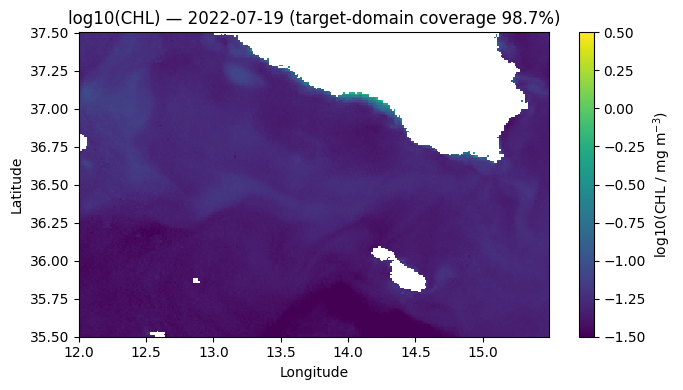

In [7]:
import matplotlib.pyplot as plt

# Select the July 2022 day with the highest coverage over
# the observable target domain.
july = chl_qc.sel(
    time=slice("2022-07-01", "2022-07-31")
)

july_coverage = (
    july.notnull()
    .where(target_domain)
    .mean(dim=["latitude", "longitude"], skipna=True)
)

best_time = july_coverage.idxmax("time")
day = july.sel(time=best_time)

day_coverage = float(
    day.notnull()
    .where(target_domain)
    .mean(skipna=True)
)

fig, ax = plt.subplots(figsize=(7, 4))

im = ax.pcolormesh(
    day.longitude,
    day.latitude,
    np.log10(day),
    shading="auto",
    cmap="viridis",
    vmin=-1.5,
    vmax=0.5,
)

date_label = str(day.time.values)[:10]

ax.set_title(
    f"log10(CHL) — {date_label} "
    f"(target-domain coverage {day_coverage * 100:.1f}%)"
)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.colorbar(
    im,
    ax=ax,
    label="log10(CHL / mg m$^{-3}$)",
)

plt.tight_layout()
plt.savefig(
    FIG_DIR / "01_chl_sample_day.png",
    dpi=150,
)
plt.show()

---
## Next: `02-Coverage-Atlas.ipynb`

Stage 2 turns the NaN pattern in this cube into a **per-month coverage diagnostic** that decides whether daily forecasting is viable, or whether the target must be a 3-day rolling composite. Do **not** skip it — winter convective blooms happen exactly when coverage is worst.